# Calculating recall answers directly from the data

This notebook explains how the pandas script calculates reference answers for
broad recall questions. Each answer comes with the campaign IDs that support it.
The answers can help the team validate the evaluation set used to compare the
LLM-only baseline, dense RAG, and keyword retrieval.

**Walkthrough:** load the snapshot → define the counting rules → count campaigns
→ compare vehicles → rank components → inspect evidence → verify the saved results.

The calculations reuse `aggregate_answers.py` in the repository root. The notebook
adds intermediate tables, explanations, and plots while the script remains the
command-line entry point.

## 1. Setup and counting rules

Select the project's `.venv` Python kernel, then **Restart Kernel and Run All**.
The notebook can start from the repository root or its `notebooks` directory.
It requires the local NHTSA `FLAT_RCL_POST_2010.txt` snapshot.

| Decision | Definition used here |
|---|---|
| Counting unit | Distinct NHTSA campaign IDs (`CAMPNO`) |
| Recall scope | Vehicle recalls (`RCLTYPECD = V`) |
| Model year | `YEARTXT`, used for the 2019 vehicle questions |
| Report year | The year of `RCDATE`, used for the 2023 questions |
| Make | Vehicle brand in `MAKETXT` |
| Component | The complete `COMPNAME` label after trimming whitespace |
| Ties | Return every winner |

In [1]:
from pathlib import Path
import hashlib
import json
import sys
import textwrap

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

# Find the script whether Jupyter starts in the root or notebooks directory.
project_root = next(
    (folder for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "aggregate_answers.py").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Open this notebook from the project root or notebooks directory.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from aggregate_answers import load_recalls, count_campaigns, top_components, main

DATA_PATH = project_root / "data/raw/FLAT_RCL_POST_2010.txt"
SAVED_RESULTS = project_root / "results/aggregate_answers.json"
MODEL_YEAR = 2019
REPORT_YEAR = 2023
RECALL_TYPE = "V"

%matplotlib inline
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11})

def show_table(frame, caption):
    """Display a compact table with wrapped text and no redundant row index."""
    display(
        frame.style.hide(axis="index").set_caption(caption)
        .set_properties(**{"text-align": "left", "white-space": "normal",
                           "max-width": "460px", "padding": "7px 10px"})
        .set_table_styles([
            {"selector": "caption", "props": [("text-align", "left"),
                ("font-weight", "bold"), ("font-size", "15px"), ("padding", "10px 0")]},
            {"selector": "th", "props": [("text-align", "left"),
                ("background-color", "#edf2f7"), ("padding", "7px 10px")]},
        ])
    )

show_table(pd.DataFrame([
    {"Function": "load_recalls(path)", "Role": "Load strings, validate required fields and report dates"},
    {"Function": "count_campaigns(df, ...)", "Role": "Filter rows, then count distinct campaign IDs"},
    {"Function": "top_components(df, year)", "Role": "Count campaigns per component and retain all ties"},
    {"Function": "main()", "Role": "Run the fixed questions and write JSON with provenance"},
]), "Functions reused from the script")

Function,Role
load_recalls(path),"Load strings, validate required fields and report dates"
"count_campaigns(df, ...)","Filter rows, then count distinct campaign IDs"
"top_components(df, year)",Count campaigns per component and retain all ties
main(),Run the fixed questions and write JSON with provenance


## 2. Load and validate the snapshot

`load_recalls` preserves the 29 raw fields as strings, trims surrounding
whitespace, and adds the parsed `report_date`. It stops if required fields are
missing, report dates are invalid, or a campaign has conflicting report dates.

It retains all campaign/vehicle/component rows. We decide what to count only
after applying the question's filters.

In [2]:
df = load_recalls(DATA_PATH)
vehicle_rows = df.loc[df["RCLTYPECD"].str.casefold().eq(RECALL_TYPE.casefold())]

show_table(pd.DataFrame([
    {"Scope": "All loaded recall types", "Rows": len(df),
     "Distinct campaigns": df["CAMPNO"].nunique()},
    {"Scope": "Vehicle recalls (V)", "Rows": len(vehicle_rows),
     "Distinct campaigns": vehicle_rows["CAMPNO"].nunique()},
]), "Dataset overview")

preview_columns = ["CAMPNO", "MAKETXT", "MODELTXT", "YEARTXT", "COMPNAME", "RCDATE"]
show_table(df[preview_columns].head(5), "Five source rows · YEARTXT and RCDATE answer different questions")

Scope,Rows,Distinct campaigns
All loaded recall types,247149,15379
Vehicle recalls (V),220402,13740


CAMPNO,MAKETXT,MODELTXT,YEARTXT,COMPNAME,RCDATE
10V525000,ITASCA,SUNRISE,2010,EQUIPMENT,20101026
10V434000,NEWMAR,KOUNTRY AIRE FW,2008,EQUIPMENT,20100922
10V434000,NEWMAR,CYPRESS FW,2007,EQUIPMENT,20100922
10V305000,AUTOCAR,WX64,2004,"FUEL SYSTEM, OTHER:STORAGE:TANK ASSEMBLY",20100628
10V305000,AUTOCAR,WXLL42,2006,"FUEL SYSTEM, OTHER:STORAGE:TANK ASSEMBLY",20100628


## 3. Why row counts are not recall counts

**Example: q25 — How many campaigns cover the 2019 Honda CR-V?**

First select vehicle recalls for the requested make, model, and model year.
A campaign may still appear more than once because the extract contains multiple
component records. The table below shows those repeated campaign IDs explicitly.

In [3]:
crv_rows = vehicle_rows.loc[
    vehicle_rows["MAKETXT"].str.casefold().eq("honda")
    & vehicle_rows["MODELTXT"].str.casefold().eq("cr-v")
    & vehicle_rows["YEARTXT"].eq(str(MODEL_YEAR))
]
crv_answer = count_campaigns(df, make="HONDA", model="CR-V", model_year=MODEL_YEAR)

show_table(pd.DataFrame([{
    "Selection": f"{MODEL_YEAR} Honda CR-V",
    "Matching rows": len(crv_rows),
    "Distinct campaigns (answer)": crv_answer["campaign_count"],
}]), "Rows versus campaigns")

crv_evidence = (
    crv_rows.groupby("CAMPNO", as_index=False)
    .agg(source_rows=("CAMPNO", "size"), components=("COMPNAME", "nunique"),
         report_date=("report_date", "first"))
    .rename(columns={"CAMPNO": "Campaign", "source_rows": "Source rows",
                     "components": "Distinct component labels", "report_date": "Report date"})
)
crv_evidence["Report date"] = crv_evidence["Report date"].dt.strftime("%Y-%m-%d")
show_table(crv_evidence, "Every campaign supporting the CR-V count")
assert set(crv_evidence["Campaign"]) == set(crv_answer["source_records"])

Selection,Matching rows,Distinct campaigns (answer)
2019 Honda CR-V,115,8


Campaign,Source rows,Distinct component labels,Report date
19V383000,4,4,2019-05-21
19V569000,1,1,2019-08-01
19V694000,1,1,2019-09-26
19V865000,1,1,2019-12-05
21V215000,36,1,2021-03-25
23V158000,36,1,2023-03-09
23V858000,34,1,2023-12-18
26V332000,2,1,2026-05-21


Repeated campaign IDs do not by themselves indicate bad data. Counting distinct
`CAMPNO` after filtering prevents those rows from inflating the answer. Removing
all repeated campaigns before filtering would lose vehicle and component details.

## 4. Count and compare the three vehicles

The same `count_campaigns` function answers q25, q30, and q31 by changing the
model parameter. Their counts then answer q33: which of the three has the most
campaigns? The comparison includes all ties.

Question,Vehicle,Campaigns
q25,2019 Honda CR-V,8
q30,2019 Honda CIVIC,4
q31,2019 Honda ACCORD,6


**q33:** CR-V — **8 campaigns**.

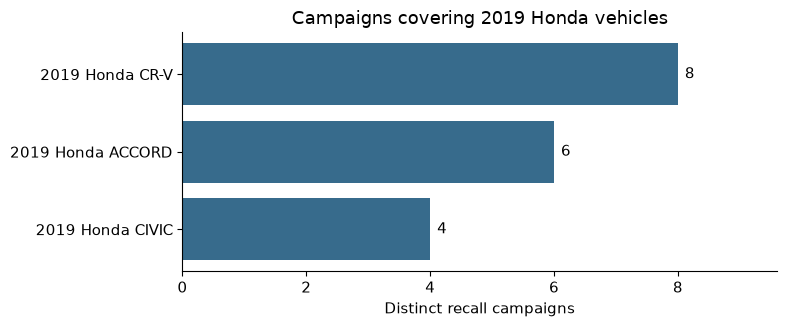

In [4]:
question_models = {"q25": "CR-V", "q30": "CIVIC", "q31": "ACCORD"}
vehicle_results = {
    model: count_campaigns(df, make="HONDA", model=model, model_year=MODEL_YEAR)
    for model in question_models.values()
}
comparison = pd.DataFrame([
    {"Question": question_id, "Vehicle": f"{MODEL_YEAR} Honda {model}",
     "Campaigns": vehicle_results[model]["campaign_count"]}
    for question_id, model in question_models.items()
])
show_table(comparison, "q25 / q30 / q31 · Distinct campaigns by vehicle")

largest_count = max(result["campaign_count"] for result in vehicle_results.values())
winning_models = sorted(
    model for model, result in vehicle_results.items()
    if result["campaign_count"] == largest_count
)
display(Markdown(f"**q33:** {', '.join(winning_models)} — **{largest_count} campaigns**."))

fig, ax = plt.subplots(figsize=(8, 3.4))
ordered = comparison.sort_values("Campaigns", ascending=True)
bars = ax.barh(ordered["Vehicle"], ordered["Campaigns"], color="#376b8c")
ax.bar_label(bars, padding=5)
ax.set(xlabel="Distinct recall campaigns", title=f"Campaigns covering {MODEL_YEAR} Honda vehicles")
ax.set_xlim(0, max(largest_count * 1.2, 1))
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()
plt.close(fig)

## 5. Report-year question

**q32 — How many campaigns covering Honda-brand vehicles were reported in 2023?**

This query filters the report date and the Honda brand. It includes all model
years. The evidence table lists one row per contributing campaign, ordered by
report date.

In [5]:
honda_by_report_year = count_campaigns(df, make="HONDA", report_year=REPORT_YEAR)
display(Markdown(
    f"**Answer:** {honda_by_report_year['campaign_count']} Honda vehicle campaigns "
    f"reported in **{REPORT_YEAR}**."
))
honda_evidence = (
    vehicle_rows.loc[
        vehicle_rows["MAKETXT"].str.casefold().eq("honda")
        & vehicle_rows["report_date"].dt.year.eq(REPORT_YEAR),
        ["CAMPNO", "report_date"],
    ]
    .drop_duplicates()
    .sort_values(["report_date", "CAMPNO"])
    .rename(columns={"CAMPNO": "Campaign", "report_date": "Report date"})
)
honda_evidence["Report date"] = honda_evidence["Report date"].dt.strftime("%Y-%m-%d")
show_table(honda_evidence, "All supporting campaigns · model year is unrestricted")
assert set(honda_evidence["Campaign"]) == set(honda_by_report_year["source_records"])

**Answer:** 19 Honda vehicle campaigns reported in **2023**.

Campaign,Report date
23V046000,2023-02-02
23V092000,2023-02-16
23V158000,2023-03-09
23V174000,2023-03-16
23V195000,2023-03-23
23V228000,2023-03-30
23V229000,2023-03-30
23V261000,2023-04-12
23V430000,2023-06-15
23V431000,2023-06-15


## 6. Which component had the most recalls?

**Definition:** vehicle recalls reported in 2023, grouped by the complete component
label. For example, `ELECTRICAL SYSTEM` and `ELECTRICAL SYSTEM:WIRING` are separate
labels in this analysis. Combining their parent categories would answer a
different question.

The intermediate table below uses `groupby("COMPNAME")["CAMPNO"].nunique()`.
A campaign contributes at most once to each component, but can contribute to
several different components. Component totals should therefore not be summed
to estimate the overall campaign count.

In [6]:
reported_rows = vehicle_rows.loc[vehicle_rows["report_date"].dt.year.eq(REPORT_YEAR)]
component_counts = (
    reported_rows.groupby("COMPNAME")["CAMPNO"]
    .nunique().rename("Campaigns").reset_index()
    .rename(columns={"COMPNAME": "Component"})
    .sort_values(["Campaigns", "Component"], ascending=[False, True])
    .reset_index(drop=True)
)
component_winners = top_components(df, REPORT_YEAR)

show_table(pd.DataFrame([{
    "Report year": REPORT_YEAR,
    "Matching rows": len(reported_rows),
    "Distinct campaigns": reported_rows["CAMPNO"].nunique(),
    "Full component labels": len(component_counts),
}]), "Scope of the component calculation")
show_table(component_counts.head(10), "Ten leading component labels · sorted by distinct campaigns")

if component_winners:
    show_table(pd.DataFrame([
        {"Winning component": item["component"], "Campaigns": item["campaign_count"],
         "Supporting IDs": len(item["source_records"])}
        for item in component_winners
    ]), "Answer returned by top_components · all first-place ties included")
else:
    display(Markdown("**No matching campaigns for this report year.**"))

Report year,Matching rows,Distinct campaigns,Full component labels
2023,19032,894,266


Component,Campaigns
ELECTRICAL SYSTEM,49
EQUIPMENT:OTHER:LABELS,30
ELECTRICAL SYSTEM: INSTRUMENT CLUSTER/PANEL,26
ELECTRICAL SYSTEM:WIRING,23
EQUIPMENT:RECREATIONAL VEHICLE/TRAILER,21
"FUEL SYSTEM, GASOLINE:DELIVERY:HOSES, LINES/PIPING, AND FITTINGS",21
STRUCTURE:BODY,21
ELECTRICAL SYSTEM:PROPULSION SYSTEM:TRACTION BATTERY,19
STRUCTURE,18
EQUIPMENT:APPLIANCE:OVEN/STOVE/COOKTOP,17


Winning component,Campaigns,Supporting IDs
ELECTRICAL SYSTEM,49,49


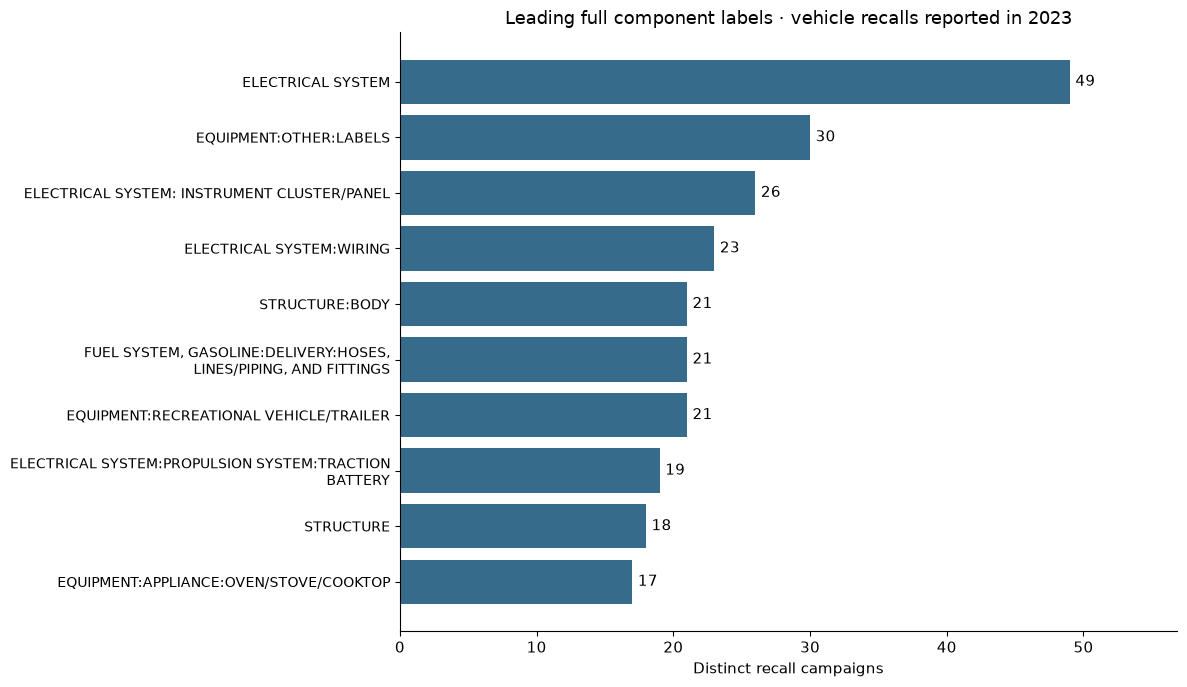

In [7]:
if not component_counts.empty:
    chart = component_counts.head(10).sort_values("Campaigns", ascending=True)
    labels = [textwrap.fill(label, width=46) for label in chart["Component"]]
    fig, ax = plt.subplots(figsize=(12, 7))
    bars = ax.barh(labels, chart["Campaigns"], color="#376b8c")
    ax.bar_label(bars, padding=4)
    ax.set(
        xlabel="Distinct recall campaigns",
        title=f"Leading full component labels · vehicle recalls reported in {REPORT_YEAR}",
    )
    ax.set_xlim(0, max(chart["Campaigns"].max() * 1.16, 1))
    ax.tick_params(axis="y", labelsize=10)
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    plt.show()
    plt.close(fig)

## 7. Inspect the evidence behind the component answer

Each winner returned by `top_components` includes its complete `source_records`
list. The tables below show up to ten supporting campaigns per winner, with the
manufacturer and report date. These are evidence samples; the count uses the
full ID list.

In [8]:
for winner in component_winners:
    evidence = (
        reported_rows.loc[
            reported_rows["COMPNAME"].eq(winner["component"])
            & reported_rows["CAMPNO"].isin(winner["source_records"]),
            ["CAMPNO", "MFGNAME", "report_date"],
        ]
        .drop_duplicates("CAMPNO")
        .sort_values(["report_date", "CAMPNO"])
        .rename(columns={"CAMPNO": "Campaign", "MFGNAME": "Manufacturer",
                         "report_date": "Report date"})
    )
    assert set(evidence["Campaign"]) == set(winner["source_records"])
    evidence["Report date"] = evidence["Report date"].dt.strftime("%Y-%m-%d")
    show_table(
        evidence.head(10),
        f"{winner['component']} · showing {min(10, len(evidence))} of "
        f"{winner['campaign_count']} supporting campaigns",
    )

Campaign,Manufacturer,Report date
23V033000,"Porsche Cars North America, Inc.",2023-01-27
23V034000,"Bentley Motors, Inc.",2023-01-27
23V132000,Hyundai Motor America,2023-02-28
23V182000,"Forest River, Inc.",2023-03-20
23V186000,KENTUCKY TRAILER MANUFACTURING,2023-03-20
23V188000,"Volvo Car USA, LLC",2023-03-22
23V190000,Alexis Fire Equipment Company,2023-03-22
23V200000,"Mercedes-Benz USA, LLC",2023-03-24
23V223000,Four Degree Trailer Company,2023-03-30
23V234000,"Winnebago Industries, Inc.",2023-03-31


## 8. Check the counting rules and the saved run

Duplicating the selected CR-V rows should leave the campaign count unchanged.
The notebook's intermediate component table should also agree with the script's
winning components and evidence counts.

A dataset hash identifies the exact input file. We compare with the committed
JSON only when both the dataset and script fingerprints match, so a newer
snapshot is not incorrectly treated as a calculation failure.

In [9]:
checks = []
doubled_crv = pd.concat([crv_rows, crv_rows], ignore_index=True)
assert count_campaigns(doubled_crv)["campaign_count"] == crv_answer["campaign_count"]
checks.append({"Check": "Duplicating CR-V rows leaves the campaign count unchanged", "Result": "Passed"})
for result in vehicle_results.values():
    assert result["campaign_count"] == len(set(result["source_records"]))
checks.append({"Check": "Vehicle counts equal their distinct supporting ID counts", "Result": "Passed"})

expected_components = (
    set(component_counts.loc[component_counts["Campaigns"].eq(component_counts["Campaigns"].max()), "Component"])
    if not component_counts.empty else set()
)
assert {item["component"] for item in component_winners} == expected_components
for item in component_winners:
    assert item["campaign_count"] == len(set(item["source_records"]))
checks.append({"Check": "Intermediate component counts and script winners agree", "Result": "Passed"})

hasher = hashlib.sha256()
with DATA_PATH.open("rb") as source:
    for block in iter(lambda: source.read(1024 * 1024), b""):
        hasher.update(block)
data_sha256 = hasher.hexdigest()
script_sha256 = hashlib.sha256((project_root / "aggregate_answers.py").read_bytes()).hexdigest()

if SAVED_RESULTS.is_file():
    saved = json.loads(SAVED_RESULTS.read_text(encoding="utf-8"))
    same_run_inputs = (
        saved["run"]["data_sha256"] == data_sha256
        and saved["run"]["script_sha256"] == script_sha256
        and (MODEL_YEAR, REPORT_YEAR, RECALL_TYPE) == (2019, 2023, "V")
    )
    if same_run_inputs:
        saved_answers = {item["id"]: item for item in saved["answers"]}
        for qid, model in question_models.items():
            for field in ("campaign_count", "source_records"):
                assert vehicle_results[model][field] == saved_answers[qid][field]
        for field in ("campaign_count", "source_records"):
            assert honda_by_report_year[field] == saved_answers["q32"][field]
        assert winning_models == saved_answers["q33"]["winners"]
        assert component_winners == saved_answers["top_component_2023"]["winners"]
        checks.append({"Check": "All six answers match the committed run on the same inputs", "Result": "Passed"})
    else:
        checks.append({"Check": "Compare with committed answers", "Result": "Skipped: snapshot, script, or parameters differ"})
else:
    checks.append({"Check": "Compare with committed answers", "Result": "Skipped: no saved JSON"})
show_table(pd.DataFrame(checks), "Validation")
show_table(pd.DataFrame([
    {"Item": "Input file", "Value": DATA_PATH.name},
    {"Item": "Dataset SHA-256", "Value": data_sha256},
    {"Item": "Script SHA-256", "Value": script_sha256},
    {"Item": "Pandas version", "Value": pd.__version__},
]), "Provenance for these calculations")

Check,Result
Duplicating CR-V rows leaves the campaign count unchanged,Passed
Vehicle counts equal their distinct supporting ID counts,Passed
Intermediate component counts and script winners agree,Passed
All six answers match the committed run on the same inputs,Passed


Item,Value
Input file,FLAT_RCL_POST_2010.txt
Dataset SHA-256,b17b92e8b712b422786dd6006713a2082eea797b2f9ea53e3ee468701f89ee57
Script SHA-256,c3e07846776628cc4bf3b598b36eb9de37607353f29485353e8d7e6cf47de6ac
Pandas version,3.1.1


## 9. Answers to bring to the team

This table collects the six answers demonstrated above. Question IDs refer to
the default 2019 model-year and 2023 report-year settings. The component-ranking
question is an additional example, not an existing numbered benchmark question.

In [10]:
summary_rows = [
    {"Question": qid, "Calculation": f"{MODEL_YEAR} Honda {model} campaigns",
     "Answer": str(vehicle_results[model]["campaign_count"])}
    for qid, model in question_models.items()
]
summary_rows.extend([
    {"Question": "q32", "Calculation": f"Honda campaigns reported in {REPORT_YEAR}",
     "Answer": str(honda_by_report_year["campaign_count"])},
    {"Question": "q33", "Calculation": "Most campaigns among the three Honda models",
     "Answer": f"{', '.join(winning_models)} ({largest_count})"},
    {"Question": "Additional", "Calculation": f"Leading full component label in {REPORT_YEAR}",
     "Answer": "; ".join(f"{item['component']} ({item['campaign_count']})" for item in component_winners)
               or "No matching campaigns"},
])
show_table(pd.DataFrame(summary_rows), "Reference-answer summary")

Question,Calculation,Answer
q25,2019 Honda CR-V campaigns,8
q30,2019 Honda CIVIC campaigns,4
q31,2019 Honda ACCORD campaigns,6
q32,Honda campaigns reported in 2023,19
q33,Most campaigns among the three Honda models,CR-V (8)
Additional,Leading full component label in 2023,ELECTRICAL SYSTEM (49)


## 10. Running the full script

`main()` loads the data, calculates the fixed q25/q30–q33 questions, and writes
JSON with supporting IDs and provenance. The optional cell below demonstrates
that entry point. It writes a separate notebook export when enabled.

The fixed questions in `main()` use model year 2019 and Honda report year 2023;
`--component-year` changes only the extra component-ranking question.

In [11]:
RUN_EXPORT = False  # Set True to generate a separate JSON using the script's main().

if RUN_EXPORT:
    export_path = project_root / "results/aggregate_answers_notebook.json"
    main([
        "--data", str(DATA_PATH),
        "--output", str(export_path),
        "--component-year", str(REPORT_YEAR),
    ])
else:
    display(Markdown(
        "**Export is off.** The walkthrough calculated the answers without changing "
        "the committed result file. Set `RUN_EXPORT = True` to run the full script."
    ))

**Export is off.** The walkthrough calculated the answers without changing the committed result file. Set `RUN_EXPORT = True` to run the full script.

## Discussion points

- Confirm whether new component questions should use full labels or broader parent categories.
- Add question definitions and supporting campaign IDs as the evaluation set grows.
- Keep each run tied to its dataset snapshot; recall counts may change in later snapshots.
- These are counts of recall campaigns. They do not measure affected vehicle totals or defect severity.

The supporting IDs let the team check whether retrieval found all the records
needed for an aggregate answer, and distinguish missing evidence from incorrect
calculation over the evidence supplied.